# Lab Class 11 — Learning Curves

**Specialized Consultancy in Data Science 1**

In Class 10, the validation curve varied **one hyperparameter** while keeping the training size fixed, answering 'what value should I use?'. Today, we freeze the model and vary the **training set size** to answer a different question: **would more data help?**

This is not a technical question; it's a financial one — labeling a thousand cases costs money. What the learning curve does is replace guesswork with evidence.

Using the same clinical dataset from Class 10: predicting which patients are at **high metabolic risk**.

## Part 0 — Environment, data, and the plotting function

Three pipelines, all utilizing `StandardScaler` before the model: within cross-validation, standardization is fitted **only on the training partition** of each fold. The metric is **ROC-AUC** — the dataset has 15% positive cases, and Class 10 already demonstrated the blind spot of accuracy here.

`plota_aprendizado` (plot_learning_curve) draws both training and validation lines with a ± 1 standard deviation band across the folds.
Run the two cells below without making any changes.

In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import (learning_curve, StratifiedKFold,
                                     cross_val_score, train_test_split)

pac = pd.read_csv("/content/1_pacientes.csv")
pac["high_risk"] = (pac["risco_metabolico"] == "alto").astype(int)
feat = [c for c in pac.columns if c not in ["id", "risco_metabolico", "high_risk", "sexo"]]
X, y = pac[feat], pac["high_risk"]

logistic = Pipeline([("scaler", StandardScaler()),
                     ("clf", LogisticRegression(max_iter=1000))])
tree15   = Pipeline([("scaler", StandardScaler()),
                     ("clf", DecisionTreeClassifier(max_depth=15, random_state=42))])
stump    = Pipeline([("scaler", StandardScaler()),
                     ("clf", DecisionTreeClassifier(max_depth=1, random_state=42))])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)   # Same folds always
frac = np.linspace(0.1, 1.0, 8)                                   # 8 training sizes

print("patients:", len(y), "| variables:", len(feat))
print("high risk:", int(y.sum()), f"({y.mean():.1%})")
print("training fractions:", np.round(frac, 3))

patients: 850 | variables: 15
high risk: 128 (15.1%)
training fractions: [0.1   0.229 0.357 0.486 0.614 0.743 0.871 1.   ]


In [3]:
def plot_learning_curve(sizes, tr, va, title):
    """sizes, tr, and va are returned by learning_curve: train_sizes, train_scores, validation_scores."""
    tr_m, tr_s = tr.mean(axis=1), tr.std(axis=1)
    va_m, va_s = va.mean(axis=1), va.std(axis=1)
    plt.figure(figsize=(8, 4.2))
    plt.plot(sizes, tr_m, "o-", color="#0F766E", label="train")
    plt.fill_between(sizes, tr_m - tr_s, tr_m + tr_s, alpha=.15, color="#0F766E")
    plt.plot(sizes, va_m, "o-", color="#B45309", label="validation")
    plt.fill_between(sizes, va_m - va_s, va_m + va_s, alpha=.15, color="#B45309")
    plt.xlabel("training examples"); plt.ylabel("ROC-AUC")
    plt.title(title); plt.legend(); plt.grid(alpha=.25)
    plt.tight_layout(); plt.show()
    return va_m[-1] - va_m[-2]        # Final slope: the gain from the last step

## Part 1 — The first learning curve

`learning_curve` takes the entire Pipeline and, for **each** training size, performs a complete cross-validation. It returns **three** outputs: the training sizes vector and two matrices (size × fold), one for training and another for validation.

Notice the difference from Class 10: there, `param_range` listed values for a hyperparameter; here, `train_sizes` lists **fractions of the training dataset**.

### Example — three sizes, to understand the output format

Before running the full sweep, let's see what the function returns with just three sizes.

In [24]:
sizes3, tr3, va3 = learning_curve(
    logistic, X, y,
    train_sizes=[0.1, 0.5, 1.0],
    cv=cv, scoring="roc_auc")

print("sizes:", sizes3, " | matrix shape:", tr3.shape, "-> 3 sizes x 5 folds")
for s, a, b in zip(sizes3, tr3.mean(axis=1), va3.mean(axis=1)):
    print(f"{s:4d} examples   train {a:.4f}   validation {b:.4f}   gap {a - b:.4f}")

sizes: [ 68 340 680]  | matrix shape: (3, 5) -> 3 sizes x 5 folds
  68 examples   train 0.9977   validation 0.9106   gap 0.0871
 340 examples   train 0.9791   validation 0.9537   gap 0.0254
 680 examples   train 0.9695   validation 0.9584   gap 0.0111


### Exercise 1 — the full logistic regression curve

Re-run the call using the **8 sizes** from the `frac` vector and plot the result using `plota_aprendizado`. Store the three outputs in `tam`, `tr`, and `va`.

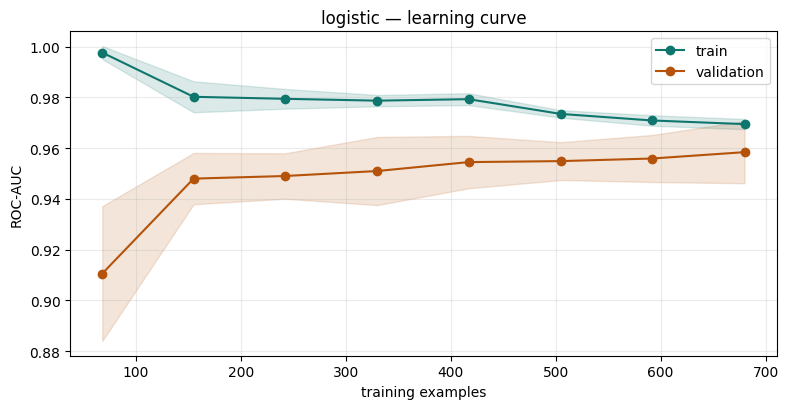

gain from the last step (final slope): 0.0025


In [25]:
# TODO: generate the learning curve for 'logistic' with train_sizes=frac
sizes, tr, va = learning_curve(
    logistic, X, y,
    train_sizes=frac,
    cv=cv, scoring="roc_auc")

m_tr, m_va, s_va = tr.mean(axis=1), va.mean(axis=1), va.std(axis=1)
slope = plot_learning_curve(sizes, tr, va, "logistic — learning curve")
print("gain from the last step (final slope):", round(slope, 4))

## Part 2 — Reading the curve: the two lines and the gap

With more training examples, the training score usually **drops** slightly (it becomes harder to memorize everything) and the validation score **rises** (the model generalizes better). The **gap** = training − validation tends to shrink.

And the rule remains unchanged: when making decisions, you look at the **validation line**. The training line serves only one purpose — compared with the validation line, it gives you the gap.

### Example — the table of the three sizes from Part 1

In [26]:
example = pd.DataFrame({"examples":   sizes3,
                        "train":      tr3.mean(axis=1).round(4),
                        "validation": va3.mean(axis=1).round(4)})
example["gap"] = (example["train"] - example["validation"]).round(4)
example

,examples,train,validation,gap
0,68,0.9977,0.9106,0.0871
1,340,0.9791,0.9537,0.0254
2,680,0.9695,0.9584,0.0111


### Exercise 2 — the full table and the gap

Build a `DataFrame` with the 8 training sizes and the columns: `treino` (training), `validação` (validation), `desvio` (standard deviation), and `gap`. Add a column `ganho` (gain) containing the validation difference from the previous step (use `.diff()`).

Answer at the end: does the gap shrink? Does validation still rise in the final step?

In [27]:
table = pd.DataFrame({"examples":   sizes,
                      "train":      m_tr.round(4),
                      "validation": m_va.round(4),
                      "std_dev":    s_va.round(4)})

# TODO: create the column 'gap' (train - validation) and 'gain' (validation difference)
table["gap"]   = (table["train"] - table["validation"]).round(4)
table["gain"]  = table["validation"].diff().round(4)
table

,examples,train,validation,std_dev,gap,gain
0,68,0.9977,0.9106,0.0266,0.0871,NaN
1,155,0.9802,0.9480,0.0101,0.0322,0.0374
2,242,0.9794,0.9490,0.0089,0.0304,0.0010
3,330,0.9787,0.9510,0.0134,0.0277,0.0020
4,417,0.9793,0.9545,0.0103,0.0248,0.0035
5,505,0.9735,0.9549,0.0075,0.0186,0.0004
6,592,0.9709,0.9559,0.0093,0.0150,0.0010
7,680,0.9695,0.9584,0.0122,0.0111,0.0025


**Answer:**

Yes, the gap shrinks consistently as the training data increases, going from \( 0.0871 \) (with 68 examples) to \( 0.0111 \) (with 680 examples).

The validation score still rises in the last step, showing a gain of \( +0.0025 \) when going from 592 to 680 examples, indicating that the model still has a slight tendency to improve with additional data.

## Part 5 — Small dataset: where the interpretation changes

With little data, you are on the **steep** part of the curve, and that is where each new batch yields the most. The curve becomes more useful, not less. However, reading it requires two precautions: the first point might be noisy, and comparisons must be done between **ranges**, not just means.

### Example — signature of a deep tree

In [28]:
sizes_tree, tr_tree, va_tree = learning_curve(tree15, X, y, train_sizes=frac,
                                             cv=cv, scoring="roc_auc")
print("train at largest size      :", round(tr_tree.mean(axis=1)[-1], 4))
print("validation at largest size :", round(va_tree.mean(axis=1)[-1], 4))
print("gap                        :", round(tr_tree.mean(axis=1)[-1] - va_tree.mean(axis=1)[-1], 4))

train at largest size      : 1.0
validation at largest size : 0.7652
gap                        : 0.2348


### Exercise 3 — the two extremes, side-by-side

Generate the learning curve for the `toco` model and plot both (deep tree and stump) using `plota_aprendizado`. Then, print the training, validation, and gap at the maximum size for all **three** models.

Answer: which is high bias and which is high variance? And for which of the two would **more data** help?

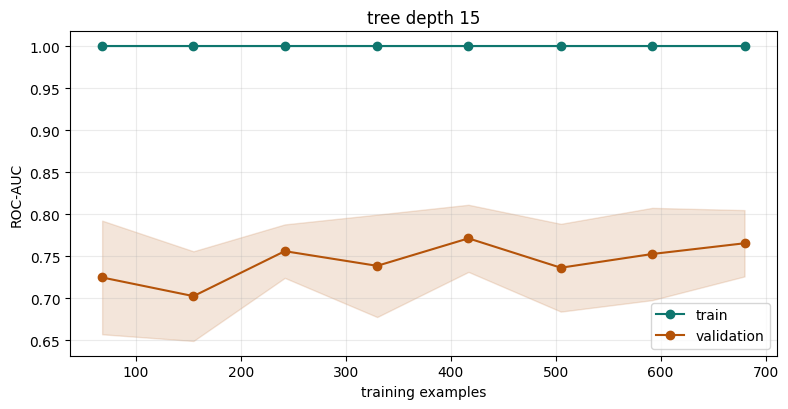

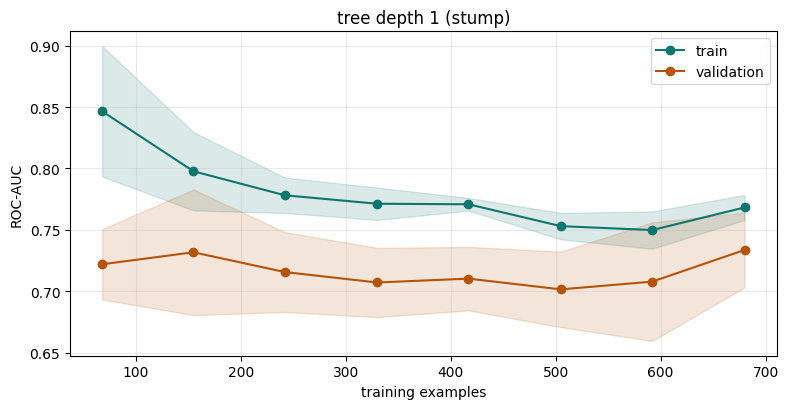

logistic   train 0.9695   validation 0.9584   gap 0.0111
tree 15    train 1.0000   validation 0.7652   gap 0.2348
stump      train 0.7682   validation 0.7336   gap 0.0346


In [29]:
plot_learning_curve(sizes_tree, tr_tree, va_tree, "tree depth 15")

# TODO: generate the curve for the 'stump' model and plot it
sizes_stump, tr_stump, va_stump = learning_curve(stump, X, y, train_sizes=frac, cv=cv, scoring='roc_auc')
plot_learning_curve(sizes_stump, tr_stump, va_stump, "tree depth 1 (stump)")

for name, t, v in [("logistic  ", tr, va), ("tree 15   ", tr_tree, va_tree), ("stump     ", tr_stump, va_stump)]:
    a, b = t.mean(axis=1)[-1], v.mean(axis=1)[-1]
    print(f"{name} train {a:.4f}   validation {b:.4f}   gap {a - b:.4f}")

**Answer:**

* **Tree of depth 15:** Shows a **high variance (overfitting)** signature, since the training score remains at \( 1.0000 \), while the validation score stays much lower (\( 0.7652 \)), leading to a large gap of \( 0.2348 \).
* **Tree of depth 1 (stump / toco):** Shows a **high bias (underfitting)** signature, with both lines quickly converging to a low level of performance (training at \( 0.7682 \) and validation at \( 0.7336 \)), with a small gap of \( 0.0346 \).

**Would more data help?**
In neither case. For the **stump**, the model has already exhausted its capacity to represent the decision boundary (plateau established). For **tree 15**, the model is completely memorizing the training set (training score of \( 1.0 \)); although more data would eventually bring the curves closer, the excess complexity without regularization will continue limiting generalizability compared to a linear model like logistic regression.

## Part 4 — The decision: is it worth collecting more data?

The baseline is the **final slope** of the validation line. If it is still rising, collecting more data will likely pay off; if it flattened into a plateau, the gain will be small and expensive.

And "small" only makes sense compared to the **standard deviation**: a gain smaller than the variation across folds is not a proven gain.

### Example — final step gain vs. standard deviation of that step

In [30]:
print(f"validation at second-to-last size ({sizes[-2]}): {m_va[-2]:.4f}")
print(f"validation at last size           ({sizes[-1]}): {m_va[-1]:.4f} ± {s_va[-1]:.4f}")
print(f"step gain       : {m_va[-1] - m_va[-2]:+.4f}")
print(f"point deviation : {s_va[-1]:.4f}   -> does gain fit inside standard deviation?",
      (m_va[-1] - m_va[-2]) < s_va[-1])

validation at second-to-last size (592): 0.9559
validation at last size           (680): 0.9584 ± 0.0122
step gain       : +0.0025
point deviation : 0.0122   -> does gain fit inside standard deviation? True


### Exercise 4 — response to the client

The client asks: *"is it worth labeling 1,000 more patients?"*. Respond with numbers.

Build a table with the **gain per step** and the **gain per 100 new examples** (gain divided by the number of examples added, multiplied by 100). Then write the final answer in one sentence, quoting the final slope and standard deviation.

In [31]:
gain = np.diff(m_va)
new_samples = np.diff(sizes)

# TODO: gain per 100 new examples
per100 = (gain / new_samples) * 100

for i in range(len(gain)):
    print(f"from {sizes[i]:3d} to {sizes[i+1]:3d} (+{new_samples[i]:3d})   "
          f"gain {gain[i]:+.4f}   per 100 examples {per100[i]:+.4f}")

from  68 to 155 (+ 87)   gain +0.0374   per 100 examples +0.0430
from 155 to 242 (+ 87)   gain +0.0010   per 100 examples +0.0012
from 242 to 330 (+ 88)   gain +0.0020   per 100 examples +0.0022
from 330 to 417 (+ 87)   gain +0.0035   per 100 examples +0.0040
from 417 to 505 (+ 88)   gain +0.0004   per 100 examples +0.0004
from 505 to 592 (+ 87)   gain +0.0010   per 100 examples +0.0012
from 592 to 680 (+ 88)   gain +0.0025   per 100 examples +0.0028


**Answer:**

It is not worth labeling another 1,000 patients. The final slope of the validation curve (the gain in the last step) is only \( +0.0025 \), corresponding to a very low projected rate of \( +0.0028 \) per 100 new examples. Since this gain is significantly smaller than the validation's standard deviation at the last point (\( 0.0122 \)), any natural sampling fluctuation would overshadow the expected improvement, indicating that the model has reached a practical performance plateau with the current dataset size.

## Parte 5 — Base pequena: onde a leitura muda

Com pouco dado você está na parte **íngreme** da curva, e é ali que cada lote novo rende mais.
A curva fica mais útil, não menos. Mas a leitura exige dois cuidados: o primeiro ponto é ruído,
e a comparação tem de ser entre **faixas**, não entre médias.

### Example — the first point with 200 rows

Let's slice the dataset to 200 patients and request a learning curve starting at 10%. The first point trains with only 16 examples — watch what happens.

In [32]:
X_small, _, y_small, _ = train_test_split(X, y, train_size=200, stratify=y, random_state=42)
print("small dataset:", len(y_small), "patients |", int(y_small.sum()), "high risk")

sizes_p, tr_p, va_p = learning_curve(logistic, X_small, y_small, train_sizes=frac,
                                     cv=cv, scoring="roc_auc")
print("\nsizes:", sizes_p)
print("validation:", np.round(va_p.mean(axis=1), 4))
print("\nThe first point trains with", sizes_p[0], "examples.")
print("Look at the warning that scikit-learn prints and the value that resulted at this point.")

small dataset: 200 patients | 30 high risk

sizes: [ 16  36  57  77  98 118 139 160]
validation: [   nan 0.9353 0.9324 0.9578 0.949  0.9569 0.9618 0.9578]

The first point trains with 16 examples.
Look at the warning that scikit-learn prints and the value that resulted at this point.


/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_validation.py:528: FitFailedWarning: 
1 fits failed out of a total of 40.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
1 fits failed with the following error:
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_validation.py", line 866, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/sklearn/base.py", line 1389, in wrapper
    return fit_method(estimator, *args, **kwargs)
  File "/usr/local/lib/python3.13/dist-packages/sklearn/pipeline.py", line 662, in fit
    self._final_estimator.fit(Xt, y, **last

### Exercise 5 — the range, not the mean

Recreate the learning curve for the small dataset starting at **25%** (`np.linspace(0.25, 1.0, 8)`) and print the validation mean and the **range** of ± 1 standard deviation for each step.

Answer: do the ranges overlap between the first and last size? Can we confidently claim the curve went up?

In [33]:
frac_p = np.linspace(0.25, 1.0, 8)

# TODO: generate the learning curve for the small dataset with train_sizes=frac_p
sizes_q, tr_q, va_q = learning_curve(
    logistic, X_small, y_small,
    train_sizes=frac_p,
    cv=cv, scoring="roc_auc")

mq, sq = va_q.mean(axis=1), va_q.std(axis=1)
for s, m, std in zip(sizes_q, mq, sq):
    print(f"{s:4d} examples   validation {m:.4f} ± {std:.4f}   range [{m - std:.3f} ; {m + std:.3f}]")

  40 examples   validation 0.9324 ± 0.0224   range [0.910 ; 0.955]
  57 examples   validation 0.9324 ± 0.0357   range [0.897 ; 0.968]
  74 examples   validation 0.9520 ± 0.0179   range [0.934 ; 0.970]
  91 examples   validation 0.9441 ± 0.0362   range [0.908 ; 0.980]
 108 examples   validation 0.9559 ± 0.0128   range [0.943 ; 0.969]
 125 examples   validation 0.9549 ± 0.0126   range [0.942 ; 0.967]
 142 examples   validation 0.9608 ± 0.0149   range [0.946 ; 0.976]
 160 examples   validation 0.9578 ± 0.0235   range [0.934 ; 0.981]


**Answer:**

Yes, the standard deviation ranges overlap significantly across almost the entire curve. The first point (40 examples) has a range of \( [0.910 ; 0.955] \), which directly intersects with the range of the last point (160 examples) of \( [0.934 ; 0.981] \).

Due to this substantial overlap caused by high variability among the validation folds, **we cannot assert with statistical confidence that the validation curve actually went up**. The natural sampling noise in this small-sample scenario makes it impossible to distinguish real improvement from random fluctuations.

## Part 6 — How much data is enough, and how much does it cost to find out?

This section answers a common question: if it's not always necessary to train on the entire dataset, **how do we know when a sample is enough** — and how do we prevent the cost of finding out from equaling the cost of training on everything?

The first question is answered by the curve for free: the sufficient size is the **smallest** one whose range already reaches the performance of the largest size. The second has an arithmetic answer.

### Example — the actual cost of computing the curve

It takes 8 sizes × 5 folds = **40 training runs**, compared to just 5 runs of a regular `cross_val_score`. However, 40 runs do not cost 8 times more because **35 of them are smaller**: the computational cost scales with the total number of **rows** trained, not the count of runs.

In [34]:
curve_rows = (frac * sizes[-1]).sum() * cv.get_n_splits()
full_rows = sizes[-1] * cv.get_n_splits()

print(f"rows trained by curve         : {curve_rows:8.0f}")
print(f"rows trained by 5 full runs   : {full_rows:8.0f}")
print(f"ratio: {curve_rows / full_rows:.1f}x  (naive counts would suggest 8.0x)")
print("\nThe sum of fractions is the factor:", round(frac.sum(), 2))

rows trained by curve         :    14960
rows trained by 5 full runs   :     3400
ratio: 4.4x  (naive counts would suggest 8.0x)

The sum of fractions is the factor: 4.4


### Exercise 6 — the sufficient dataset size

Calculate the **floor** of the range for the largest size (mean minus one standard deviation) and find the **smallest** training size whose mean is already above this floor. Print this size, its validation score, and what fraction of the full training set it represents.

Answer: with how many patients does this dataset already deliver the performance of the end of the curve?

In [35]:
# TODO: floor = average of last point minus standard deviation of THAT point
floor = m_va[-1] - s_va[-1]

inside = [(int(s), v) for s, v in zip(sizes, m_va) if v >= floor]
sufficient, v_suf = inside[0]

print(f"range of the largest size : {m_va[-1]:.4f} ± {s_va[-1]:.4f}  -> floor {floor:.4f}")
print(f"smallest size reaching floor: {sufficient} examples  (validation {v_suf:.4f})")
print(f"this is {sufficient / sizes[-1]:.0%} of the available training data")

range of the largest size : 0.9584 ± 0.0122  -> floor 0.9462
smallest size reaching floor: 155 examples  (validation 0.9480)
this is 23% of the available training data


**Answer:**

This dataset already delivers a performance statistically equivalent to the end of the curve with only **155 patients** (representing about \( 23\% \) of the total available training data). At this size, the average validation score reaches \( 0.9480 \), which is already above the floor of \( 0.9462 \) (the lower limit of the standard deviation range of the largest training size, \( 0.9584 \pm 0.0122 \)).

## Part 7 — The curve outside the Pipeline

The learning curve runs cross-validation 8 times. If preprocessing is performed **outside** the Pipeline — standardizing the entire dataset before calling the function — the standardization leaks information from the validation fold at all 8 sizes. This is the same error discussed in Classes 05 to 07, multiplied.

### Example — standardizing the matrix all at once

In [37]:
X_z = pd.DataFrame(StandardScaler().fit_transform(X), columns=feat)
print("scaled across the ENTIRE dataset — mean and std dev of one column:")
print(round(X_z[feat[0]].mean(), 6), round(X_z[feat[0]].std(), 4))

scaled across the ENTIRE dataset — mean and std dev of one column:
0.0 1.0006


### Exercise 7 — the error that doesn't trigger alarms

Generate the learning curve of a **raw** `LogisticRegression` (without a Pipeline) over `X_z`, using the same `frac` and `cv`, and compare the validation score point-by-point with the correct curve from Part 1.

Answer: is the difference significant? And if it is small, why is that a problem rather than a relief?

In [38]:
# TODO: curve for LogisticRegression(max_iter=1000) on X_z, without Pipeline
sizes_z, tr_z, va_z = learning_curve(
    LogisticRegression(max_iter=1000),
    X_z, y,
    train_sizes=frac,
    cv=cv,
    scoring="roc_auc"
)

for s, outside, inside in zip(sizes_z, va_z.mean(axis=1), m_va):
    print(f"{s:4d}   outside Pipeline {outside:.4f}   inside {inside:.4f}   "
          f"difference {outside - inside:+.4f}")

  68   outside Pipeline 0.9078   inside 0.9106   difference -0.0028
 155   outside Pipeline 0.9476   inside 0.9480   difference -0.0004
 242   outside Pipeline 0.9491   inside 0.9490   difference +0.0001
 330   outside Pipeline 0.9510   inside 0.9510   difference +0.0000
 417   outside Pipeline 0.9546   inside 0.9545   difference +0.0001
 505   outside Pipeline 0.9548   inside 0.9549   difference -0.0001
 592   outside Pipeline 0.9559   inside 0.9559   difference -0.0001
 680   outside Pipeline 0.9584   inside 0.9584   difference -0.0001


**Answer:**

The practical difference observed is extremely small, reaching at most \( -0.0028 \) at the first point and stabilizing to virtually zero (e.g., \( -0.0001 \)) for larger sizes.

While this might seem like good news, **this behavior is a serious issue precisely because it does not trigger any alarms**. Since data leakage occurs silently and the change in metrics is almost imperceptible, a developer might easily reuse this flawed methodology in future projects without realizing. In real-world scenarios where preprocessing is more complex and aggressive (such as target-based feature selection, missing value imputation, or supervised dimensionality reduction), the leakage's impact will be devastatingly larger, artificially inflating the validation scores without the methodological error ever being caught early.

---

**Congratulations!** You built learning curves for three models, interpreted the two signatures, translated the final slope into a business answer, observed the first point fail on a small dataset, calculated the sufficient sample size and the cost to find it, and measured silent data leakage.

To carry over to your integrated project: before asking the client for more data, plot the learning curve. If validation has flattened, the request is not justified — and if it is still rising, you have the visual evidence to justify the budget.

In the next class (03/11): **model selection and comparison, decision thresholds, and calibration**.